In [1]:
import os
os.environ["OMP_NUM_THREADS"] = "1"
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

In [2]:
data = pd.read_csv("Mall_Customers.csv")
data.columns = data.columns.str.strip()
print("First 5 rows of the dataset:")
print(data.head())
print("\nColumn names:")
print(data.columns.tolist())



First 5 rows of the dataset:
   CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)
0           1    Male   19                  15                      39
1           2    Male   21                  15                      81
2           3  Female   20                  16                       6
3           4  Female   23                  16                      77
4           5  Female   31                  17                      40

Column names:
['CustomerID', 'Gender', 'Age', 'Annual Income (k$)', 'Spending Score (1-100)']


In [3]:
required_columns = ['Annual Income (k$)', 'Spending Score (1-100)']
missing_columns = [col for col in required_columns if col not in data.columns]
if missing_columns:
    raise ValueError(
        f"Missing required column(s): {missing_columns}. "
        f"Available columns: {data.columns.tolist()}"
    )




In [4]:
X = data[required_columns].dropna().values
print("\nSelected Features:")
print(X[:5])




Selected Features:
[[15 39]
 [15 81]
 [16  6]
 [16 77]
 [17 40]]


In [5]:
wcss = []
for k in range(1, 11):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    model.fit(X)
    wcss.append(model.inertia_)



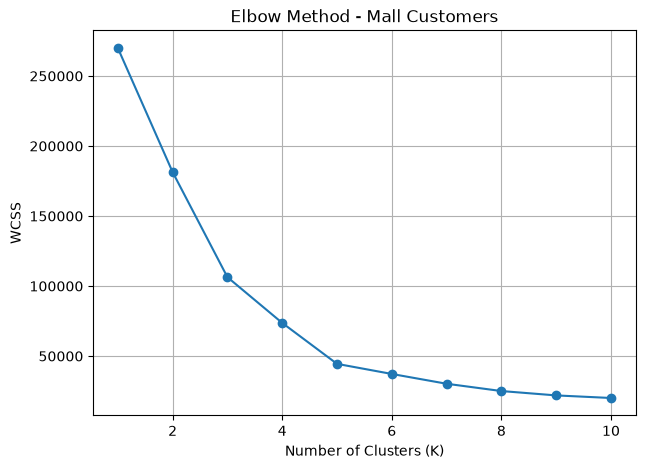

In [6]:
plt.figure(figsize=(7, 5))
plt.plot(
    range(1, 11),
    wcss,
    marker='o'
)
plt.title("Elbow Method - Mall Customers")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS")
plt.grid(True)
plt.show()



In [7]:
print("Silhouette Scores")
silhouette_scores = []
for k in range(2, 11):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    labels = model.fit_predict(X)
    score = silhouette_score(X, labels)
    silhouette_scores.append(score)
    print("K =", k, " Score =", round(score, 3))



Silhouette Scores
K = 2  Score = 0.297
K = 3  Score = 0.468
K = 4  Score = 0.493
K = 5  Score = 0.554
K = 6  Score = 0.54
K = 7  Score = 0.529
K = 8  Score = 0.455
K = 9  Score = 0.456
K = 10  Score = 0.441


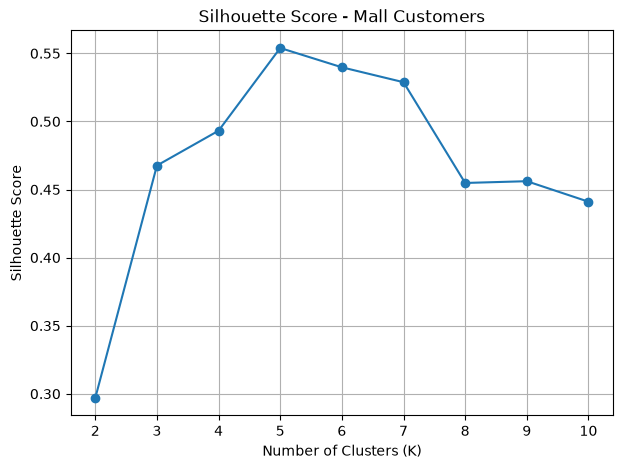

In [8]:
plt.figure(figsize=(7, 5))
plt.plot(
    range(2, 11),
    silhouette_scores,
    marker='o'
)
plt.title("Silhouette Score - Mall Customers")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.grid(True)
plt.show()



In [9]:
kmeans = KMeans(
    n_clusters=5,
    random_state=42,
    n_init=10
)

clusters = kmeans.fit_predict(X)

data['Cluster'] = clusters
print("\nClustered Dataset:")
print(data.head(10))

print("\nNumber of Customers in Each Cluster:")
print(data['Cluster'].value_counts().sort_index())


Clustered Dataset:
   CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)  \
0           1    Male   19                  15                      39   
1           2    Male   21                  15                      81   
2           3  Female   20                  16                       6   
3           4  Female   23                  16                      77   
4           5  Female   31                  17                      40   
5           6  Female   22                  17                      76   
6           7  Female   35                  18                       6   
7           8  Female   23                  18                      94   
8           9    Male   64                  19                       3   
9          10  Female   30                  19                      72   

   Cluster  
0        4  
1        2  
2        4  
3        2  
4        4  
5        2  
6        4  
7        2  
8        4  
9        2  

Number of Customers i

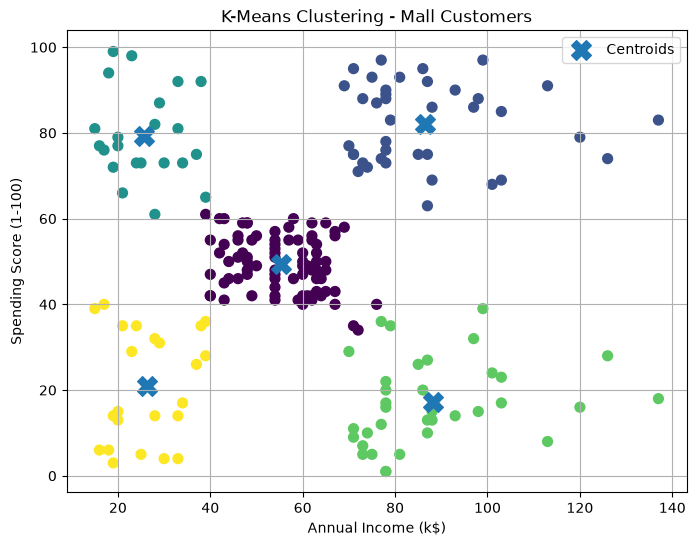

In [10]:


plt.figure(figsize=(8, 6))
plt.scatter(
    X[:, 0],
    X[:, 1],
    c=clusters,
    s=50
)
plt.scatter(
    kmeans.cluster_centers_[:, 0],
    kmeans.cluster_centers_[:, 1],
    marker='X',
    s=200,
    label='Centroids'
)
plt.title("K-Means Clustering - Mall Customers")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.legend()
plt.grid(True)
plt.show()